# NLP Lab 05 — Sequence Models: RNN, LSTM and GRU

**Dataset:** IMDb movie reviews, binary sentiment classification.  
**Framework:** TensorFlow/Keras. Run cells in order.

## 0. Imports and reproducibility

In [16]:
import os
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

OUTPUT_DIR = Path(".")
VOCAB_SIZE = 20_000
EMBEDDING_DIM = 64
BATCH_SIZE = 128
EPOCHS = 5                 # Use the same value for RNN/LSTM/GRU comparisons
MAX_LENGTH = 200
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Output directory:", OUTPUT_DIR.resolve())

TensorFlow: 2.21.0
Output directory: C:\Users\ADMIN\NLP_Apps_Labs\lab05


## 1. Load IMDb and inspect the dataset

The Keras IMDb version is already tokenized into integer IDs. The word index is used below to reconstruct readable text for the TF-IDF baseline and error analysis. Integer `0` is padding; `1` is the start token; `2` represents an out-of-vocabulary token.

In [17]:
(train_sequences, y_train_full), (test_sequences, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
word_index = imdb.get_word_index()

# Keras reserves IDs 0, 1 and 2 for padding/start/OOV; review IDs are shifted by 3.
index_to_word = {idx + 3: word for word, idx in word_index.items()}
index_to_word[0] = "<PAD>"
index_to_word[1] = "<START>"
index_to_word[2] = "<OOV>"

def decode_review(sequence):
    return " ".join(index_to_word.get(int(token), "<OOV>") for token in sequence if int(token) > 2)

train_texts_full = [decode_review(seq) for seq in train_sequences]
test_texts = [decode_review(seq) for seq in test_sequences]

X_train_seq, X_val_seq, y_train, y_val = train_test_split(
    train_sequences, y_train_full, test_size=0.2,
    random_state=SEED, stratify=y_train_full
)

all_lengths = np.array([len(seq) for seq in train_sequences] + [len(seq) for seq in test_sequences])
labels_all = np.concatenate([y_train_full, y_test])

print("Train samples:", len(train_sequences))
print("Test samples:", len(test_sequences))
print("Total samples:", len(labels_all))
print("Classes (0=negative, 1=positive):", np.unique(labels_all))
print("Class counts:", pd.Series(labels_all).value_counts().sort_index().to_dict())
print("Missing text/label: 0 (Keras IMDb is supplied as token sequences and labels)")
print("Duplicate review count: not checked on raw source text; Keras release does not expose raw-row IDs here.")
print(pd.Series(all_lengths).describe(percentiles=[.25, .5, .75]).rename("review_length"))

Train samples: 25000
Test samples: 25000
Total samples: 50000
Classes (0=negative, 1=positive): [0 1]
Class counts: {0: 25000, 1: 25000}
Missing text/label: 0 (Keras IMDb is supplied as token sequences and labels)
Duplicate review count: not checked on raw source text; Keras release does not expose raw-row IDs here.
count    50000.000000
mean       234.758920
std        172.913224
min          7.000000
25%        129.000000
50%        176.000000
75%        285.000000
max       2494.000000
Name: review_length, dtype: float64


,statistic,tokens
0,min,7.00000
1,median,176.00000
2,mean,234.75892
3,max,2494.00000


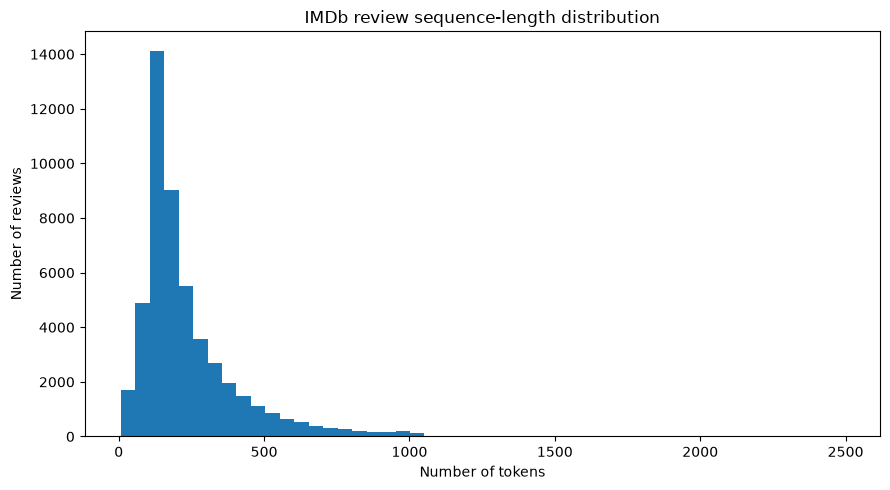

,count
class,
positive,25000
negative,25000


In [18]:
length_summary = pd.DataFrame({
    "statistic": ["min", "median", "mean", "max"],
    "tokens": [
        int(np.min(all_lengths)),
        float(np.median(all_lengths)),
        float(np.mean(all_lengths)),
        int(np.max(all_lengths)),
    ]
})
display(length_summary)

plt.figure(figsize=(9, 5))
plt.hist(all_lengths, bins=50)
plt.title("IMDb review sequence-length distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.savefig("sequence_length_histogram.png", dpi=160)
plt.show()

class_counts = pd.Series(labels_all).map({0:"negative", 1:"positive"}).value_counts()
display(class_counts.rename_axis("class").to_frame("count"))

**Nếu phải chọn max_length, nên chọn dựa trên thông tin nào?**
> Nên chọn max_length dựa trên phân bố độ dài của các review trong dataset, tỷ lệ token được giữ lại sau khi cắt chuỗi, và kết quả đánh giá của mô hình. Nếu max_length quá nhỏ, mô hình có thể mất những thông tin quan trọng để xác định cảm xúc. Ngược lại, nếu max_length quá lớn, chi phí tính toán và thời gian huấn luyện có thể tăng. Vì vậy, nên thử nghiệm các giá trị khác nhau như 50, 100 và 200, sau đó so sánh F1-score, accuracy và thời gian huấn luyện để chọn giá trị phù hợp nhất.

## 2. Padding/truncation and max-length comparison

We compare maximum sequence lengths 50, 100 and 200. Padding is added at the end and long sequences are truncated at the end (`truncating="post"`), preserving the start of each review. The retained-token percentage is an approximate token-retention statistic over all original sequences.

In [19]:
def pad_data(sequences, max_length):
    return pad_sequences(
        sequences, maxlen=max_length, padding="post", truncating="post", value=0
    )

def retained_token_percentage(sequences, max_length):
    total = sum(len(s) for s in sequences)
    kept = sum(min(len(s), max_length) for s in sequences)
    return 100.0 * kept / total if total else 0.0

for length in [50, 100, 200]:
    print(f"max_length={length}: retained token percentage = "
          f"{retained_token_percentage(list(train_sequences) + list(test_sequences), length):.2f}%")

X_train_pad = pad_data(X_train_seq, MAX_LENGTH)
X_val_pad = pad_data(X_val_seq, MAX_LENGTH)
X_test_pad = pad_data(test_sequences, MAX_LENGTH)
print("Padded shapes:", X_train_pad.shape, X_val_pad.shape, X_test_pad.shape)

max_length=50: retained token percentage = 21.22%
max_length=100: retained token percentage = 41.05%
max_length=200: retained token percentage = 68.24%
Padded shapes: (20000, 200) (5000, 200) (25000, 200)


**Tăng max_length có luôn cải thiện performance không?**
> Tăng max_length không phải lúc nào cũng cải thiện performance. Khi max_length tăng, mô hình có thể tiếp nhận nhiều thông tin hơn từ review, giúp hiểu ngữ cảnh tốt hơn. Tuy nhiên, độ dài chuỗi lớn hơn cũng làm tăng thời gian và chi phí tính toán, trong khi phần thông tin bổ sung có thể không cần thiết cho việc phân loại cảm xúc. Vì vậy, cần so sánh các chỉ số như accuracy, F1-score và thời gian huấn luyện để tìm ra giá trị phù hợp nhất.

**Nếu max_length quá nhỏ, loại thông tin nào có thể bị mất?**
> Nếu max_length quá nhỏ, các từ hoặc câu quan trọng nằm ở phần bị cắt bỏ của review có thể bị mất. Điều này có thể khiến mô hình không nhận biết được cảm xúc đầy đủ, chẳng hạn như những từ thể hiện khen ngợi hoặc chê bai, thông tin phủ định như “not good”, hay nội dung ở cuối câu làm thay đổi ý nghĩa của phần trước. Vì vậy, việc cắt chuỗi quá ngắn có thể làm giảm khả năng phân loại cảm xúc chính xác.

## 3. Implement and test `SimpleRNNCell`

This cell imports the implementation from `rnn_cell.py` and checks the one-step output shape. The framework comparison uses a Keras `SimpleRNNCell`; weights are copied so outputs can be compared fairly.

In [20]:
from rnn_cell import SimpleRNNCell

input_size, hidden_size, batch_size = 4, 6, 3
x_t = tf.random.normal((batch_size, input_size), seed=SEED)
h_prev = tf.random.normal((batch_size, hidden_size), seed=SEED + 1)

manual_cell = SimpleRNNCell(input_size=input_size, hidden_size=hidden_size)
manual_output = manual_cell(x_t, h_prev)

keras_cell = layers.SimpleRNNCell(hidden_size, activation="tanh", use_bias=True)
_ = keras_cell(x_t, [h_prev])  # Build variables

# Keras kernel: (input_size, hidden_size); recurrent_kernel: (hidden_size, hidden_size)
keras_cell.set_weights([manual_cell.W_xh.numpy(), manual_cell.W_hh.numpy(), manual_cell.b_h.numpy()])
keras_output, _ = keras_cell(x_t, [h_prev])

print("Manual output shape:", manual_output.shape)
print("Keras output shape:", keras_output.shape)
print("Maximum absolute difference:", float(tf.reduce_max(tf.abs(manual_output - keras_output))))
assert np.allclose(manual_output.numpy(), keras_output.numpy(), atol=1e-5)
print("PASS: manual cell agrees with Keras cell after copying weights.")

Manual output shape: (3, 6)
Keras output shape: (3, 6)
Maximum absolute difference: 0.0
PASS: manual cell agrees with Keras cell after copying weights.


**RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không?**
> Có. RNN xử lý các từ theo thứ tự xuất hiện và có thể học mối quan hệ giữa chúng, trong khi TF-IDF thường không giữ lại thứ tự từ. Tuy nhiên, RNN không phải lúc nào cũng cho kết quả tốt hơn TF-IDF, mà còn phụ thuộc vào dữ liệu và kết quả thực nghiệm.

## 4. TF-IDF + Logistic Regression baseline

This baseline uses the same train/validation/test split as the sequence models. For speed, TF-IDF uses unigrams and a capped feature vocabulary.

In [21]:
# Decode the exact split used above.
X_train_text = [decode_review(seq) for seq in X_train_seq]
X_val_text = [decode_review(seq) for seq in X_val_seq]
y_train_arr = np.asarray(y_train)
y_val_arr = np.asarray(y_val)
y_test_arr = np.asarray(y_test)

tfidf = TfidfVectorizer(max_features=20_000, ngram_range=(1, 1), min_df=2)
tfidf_start = time.perf_counter()
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(test_texts)
tfidf_vectorize_seconds = time.perf_counter() - tfidf_start

tfidf_model = LogisticRegression(max_iter=1000, random_state=SEED)
tfidf_fit_start = time.perf_counter()
tfidf_model.fit(X_train_tfidf, y_train_arr)
tfidf_training_seconds = time.perf_counter() - tfidf_fit_start
tfidf_pred = tfidf_model.predict(X_test_tfidf)

def metric_row(name, y_true, y_pred, training_time, params=None, epochs=None,
               max_length=None, vocab_size=None, retained_pct=None, val_loss=None):
    return {
        "experiment": "model_comparison",
        "model": name,
        "max_length": max_length,
        "vocab_size": vocab_size,
        "parameters": params,
        "epochs": epochs,
        "training_time_seconds": training_time,
        "tokens_retained_pct": retained_pct,
        "validation_loss": val_loss,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

results_rows = []
results_rows.append(metric_row(
    "TF-IDF + Logistic Regression", y_test_arr, tfidf_pred,
    tfidf_training_seconds + tfidf_vectorize_seconds,
    params=int(X_train_tfidf.shape[1]), vocab_size=int(X_train_tfidf.shape[1])
))
print(classification_report(y_test_arr, tfidf_pred, target_names=["negative", "positive"], zero_division=0))

              precision    recall  f1-score   support

    negative       0.88      0.88      0.88     12500
    positive       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



## 5. Build a shared sequence-classifier function

All recurrent models use the same split, vocabulary size, embedding dimension, batch size, optimizer, learning rate, and epoch count. The model returns a sigmoid probability for positive sentiment.

In [22]:
def build_sequence_model(model_type="SimpleRNN", max_length=MAX_LENGTH,
                         vocab_size=VOCAB_SIZE, embedding_dim=EMBEDDING_DIM):
    inputs = layers.Input(shape=(max_length,), dtype="int32", name="token_ids")
    x = layers.Embedding(
        input_dim=vocab_size, output_dim=embedding_dim,
        mask_zero=True, name="embedding"
    )(inputs)

    if model_type == "SimpleRNN":
        x = layers.SimpleRNN(64, name="simple_rnn")(x)
    elif model_type == "LSTM":
        x = layers.LSTM(64, name="lstm")(x)
    elif model_type == "GRU":
        x = layers.GRU(64, name="gru")(x)
    else:
        raise ValueError("model_type must be SimpleRNN, LSTM or GRU")

    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="sentiment")(x)
    model = models.Model(inputs, outputs, name=f"{model_type}_classifier")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def fit_evaluate_recurrent(model_type, max_length=MAX_LENGTH, epochs=EPOCHS, verbose=1):
    x_train = pad_data(X_train_seq, max_length)
    x_val = pad_data(X_val_seq, max_length)
    x_test = pad_data(test_sequences, max_length)

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = build_sequence_model(model_type, max_length=max_length)
    started = time.perf_counter()
    history = model.fit(
        x_train, y_train_arr,
        validation_data=(x_val, y_val_arr),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        verbose=verbose
    )
    training_seconds = time.perf_counter() - started
    val_loss = float(min(history.history["val_loss"]))
    probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype("int32")
    row = metric_row(
        model_type, y_test_arr, predictions, training_seconds,
        params=model.count_params(), epochs=epochs, max_length=max_length,
        vocab_size=VOCAB_SIZE,
        retained_pct=retained_token_percentage(list(train_sequences) + list(test_sequences), max_length),
        val_loss=val_loss
    )
    return model, history, predictions, probabilities, row

print("Model builder ready.")

Model builder ready.


## 6. Train SimpleRNN, LSTM and GRU

This is the main model comparison. Keep the same epoch count for all three. If runtime is too long, lower `EPOCHS` for a smoke test, then restore the same final value before recording results.

In [23]:
recurrent_runs = {}
for model_type in ["SimpleRNN", "LSTM", "GRU"]:
    print("\\n" + "=" * 60)
    print("Training:", model_type)
    run = fit_evaluate_recurrent(model_type, max_length=MAX_LENGTH, epochs=EPOCHS)
    recurrent_runs[model_type] = run
    results_rows.append(run[4])
    print(pd.DataFrame([run[4]]).to_string(index=False))

comparison_df = pd.DataFrame(results_rows)
display(comparison_df)

\n============================================================
Training: SimpleRNN
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5318 - loss: 0.6915 - val_accuracy: 0.6130 - val_loss: 0.6658
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.7286 - loss: 0.5596 - val_accuracy: 0.7250 - val_loss: 0.5580
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8389 - loss: 0.3850 - val_accuracy: 0.5934 - val_loss: 0.7941
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.9451 - loss: 0.1680 - val_accuracy: 0.6542 - val_loss: 0.8178
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9901 - loss: 0.0456 - val_accuracy: 0.7030 - val_loss: 0.8268
      experiment     model  max_length  vocab_size  parameters  epochs  training_time_seconds  tokens_retained_pct  validation_loss  accuracy  precision  recall       f1
model_comparison SimpleRNN         200       20000     1288321       5              31.862174            68

,experiment,model,max_length,vocab_size,parameters,epochs,training_time_seconds,tokens_retained_pct,validation_loss,accuracy,precision,recall,f1
0,model_comparison,TF-IDF + Logistic Regression,NaN,19179,19179,NaN,5.338891,NaN,NaN,0.88256,0.881279,0.88424,0.882757
1,model_comparison,SimpleRNN,200.0,20000,1288321,5.0,31.862174,68.235899,0.558048,0.69944,0.715620,0.66192,0.687723
2,model_comparison,LSTM,200.0,20000,1313089,5.0,70.921714,68.235899,0.396706,0.79616,0.763338,0.85848,0.808118
3,model_comparison,GRU,200.0,20000,1305025,5.0,69.914857,68.235899,0.365518,0.81744,0.821765,0.81072,0.816205


**Kết quả thực nghiệm có phù hợp với prediction ban đầu không?**
1. Prediction 1: Không phù hợp với kết quả thực nghiệm. TF-IDF + Logistic Regression đạt F1 = 0.8828, cao hơn SimpleRNN với F1 = 0.6877. Điều này cho thấy khả năng xử lý thứ tự từ của RNN chưa giúp mô hình đạt hiệu suất tốt hơn trong thí nghiệm này.

2. Prediction 2: Phù hợp một phần. LSTM đạt F1 = 0.8081, cao hơn SimpleRNN (0.6877), cho thấy kết quả tốt hơn trong thí nghiệm này. Tuy nhiên, chưa thể khẳng định nguyên nhân là do khả năng xử lý phụ thuộc dài hạn.

3. Prediction 3: Chưa đủ dữ liệu để kết luận. Kết quả hiện tại chỉ cho thấy thời gian huấn luyện của các mô hình với max_length=200; cần so sánh thêm với max_length=50 để xác định thời gian có tăng và vanishing gradient có nghiêm trọng hơn hay không.

4. Prediction 4: Chưa đủ dữ liệu để kết luận. Cần chạy thí nghiệm với max_length=30 và so sánh hiệu suất để xác định việc cắt review có làm mất thông tin quan trọng hay không.

5. Prediction 5: Phù hợp với kết quả thực nghiệm. LSTM không đạt accuracy cao hơn SimpleRNN trong mọi trường hợp nói chung; tuy nhiên, trong bảng này LSTM có accuracy cao hơn SimpleRNN (0.7962 so với 0.6994). Điều này cho thấy cần dựa vào kết quả thực nghiệm thay vì mặc định mô hình phức tạp hơn luôn tốt hơn.

## 7. Max-length experiment: 50, 100 and 200

\nTraining SimpleRNN with max_length=50
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6910 - loss: 0.5842 - val_accuracy: 0.7686 - val_loss: 0.4990
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8456 - loss: 0.3705 - val_accuracy: 0.7698 - val_loss: 0.5192
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9243 - loss: 0.2117 - val_accuracy: 0.7548 - val_loss: 0.6642
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9513 - loss: 0.1347 - val_accuracy: 0.7688 - val_loss: 0.7032
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9728 - loss: 0.0801 - val_accuracy: 0.7490 - val_loss: 0.7969
\nTraining SimpleRNN with max_length=100
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.6919 - loss: 0.5799 - val_accuracy: 0.8058 - val_loss: 0.4497
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8619 - loss: 0.3440 - val_accuracy: 0.7872 - val_loss: 0.5369
Epoch 3/5
157/157 ━━━━━

,max_length,tokens_retained_pct,training_time_seconds,validation_loss,accuracy,precision,recall,f1
0,50,21.218653,12.647611,0.499011,0.72064,0.699710,0.77304,0.734550
1,100,41.045776,19.318393,0.449686,0.76944,0.735524,0.84144,0.784925
2,200,68.235899,31.508349,0.493339,0.75652,0.752222,0.76504,0.758577


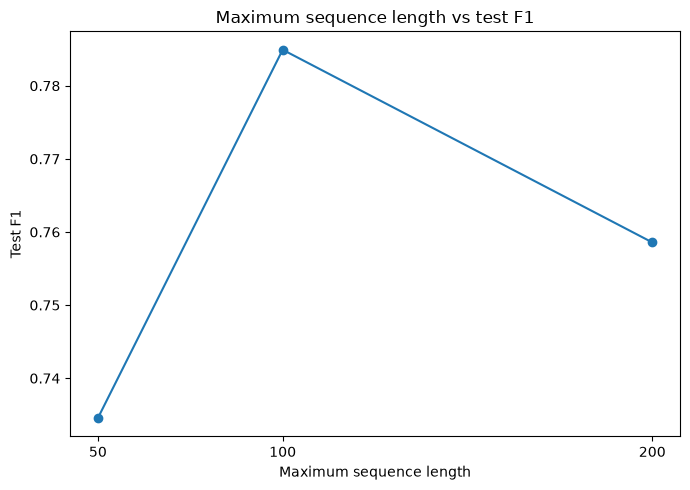

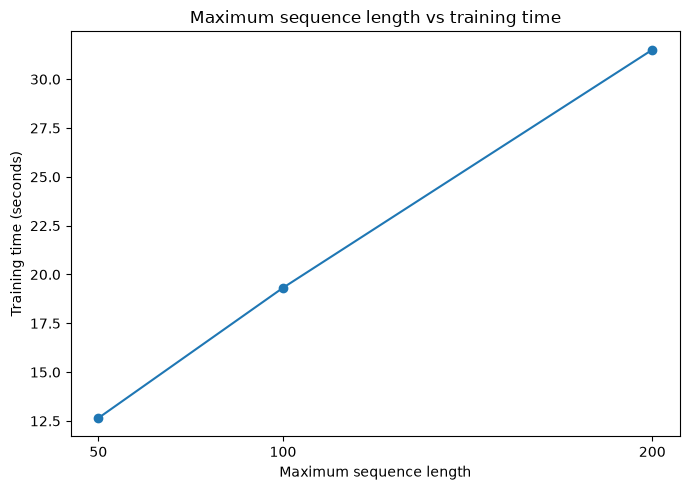

In [24]:
MAX_LENGTH_EPOCHS = EPOCHS
length_runs = {}
length_rows = []

for length in [50, 100, 200]:
    print(f"\\nTraining SimpleRNN with max_length={length}")
    model, history, pred, prob, row = fit_evaluate_recurrent(
        "SimpleRNN", max_length=length, epochs=MAX_LENGTH_EPOCHS, verbose=1
    )
    length_runs[length] = (model, history, pred, prob, row)
    row = dict(row)
    row["experiment"] = "max_length_experiment"
    length_rows.append(row)

length_df = pd.DataFrame(length_rows)
display(length_df[[
    "max_length", "tokens_retained_pct", "training_time_seconds",
    "validation_loss", "accuracy", "precision", "recall", "f1"
]])

plt.figure(figsize=(7, 5))
plt.plot(length_df["max_length"], length_df["f1"], marker="o")
plt.xticks([50, 100, 200])
plt.title("Maximum sequence length vs test F1")
plt.xlabel("Maximum sequence length")
plt.ylabel("Test F1")
plt.tight_layout()
plt.savefig("max_length_vs_f1.png", dpi=160)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(length_df["max_length"], length_df["training_time_seconds"], marker="o")
plt.xticks([50, 100, 200])
plt.title("Maximum sequence length vs training time")
plt.xlabel("Maximum sequence length")
plt.ylabel("Training time (seconds)")
plt.tight_layout()
plt.savefig("max_length_vs_training_time.png", dpi=160)
plt.show()

**Có tồn tại trade-off giữa context và computational cost không?**
> Có. Khi tăng max_length từ 50 lên 200, tỷ lệ token được giữ lại tăng từ 21,22% lên 68,24%, nhưng thời gian huấn luyện cũng tăng. Điều này cho thấy có sự đánh đổi giữa việc giữ nhiều ngữ cảnh hơn và chi phí tính toán. Tuy nhiên, F1-score không tăng đều theo max_length, nên chuỗi dài hơn không đảm bảo mô hình hoạt động tốt hơn.

## 8. Long-range dependency probe

In [25]:
long_range_examples = [
    "excellent. The movie was, despite many unnecessary scenes, ultimately ordinary.",
    "The movie was excellent, despite many unnecessary scenes, ultimately ordinary.",
    "The movie was, despite many unnecessary scenes, ultimately excellent.",
    "terrible. The movie was, despite many unnecessary scenes, ultimately ordinary.",
    "The movie was terrible, despite many unnecessary scenes, ultimately ordinary.",
    "The movie was, despite many unnecessary scenes, ultimately terrible.",
]
probe_sequences = []
for text in long_range_examples:
    # Use Keras word index encoding with OOV for unknown words.
    ids = [1]
    for word in text.lower().split():
        word = "".join(ch for ch in word if ch.isalnum() or ch == "'")
        if not word:
            continue
        raw_idx = word_index.get(word)
        token_id = (raw_idx + 3) if raw_idx is not None and raw_idx + 3 < VOCAB_SIZE else 2
        ids.append(token_id)
    probe_sequences.append(ids)

probe_padded = pad_data(probe_sequences, MAX_LENGTH)
probe_model = recurrent_runs["SimpleRNN"][0]
probe_probs = probe_model.predict(probe_padded, verbose=0).ravel()
probe_df = pd.DataFrame({
    "text": long_range_examples,
    "positive_probability": probe_probs,
    "predicted_sentiment": np.where(probe_probs >= 0.5, "positive", "negative")
})
display(probe_df)

,text,positive_probability,predicted_sentiment
0,"excellent. The movie was, despite many unneces...",0.989011,positive
1,"The movie was excellent, despite many unnecess...",0.743279,positive
2,"The movie was, despite many unnecessary scenes...",0.294492,negative
3,"terrible. The movie was, despite many unnecess...",0.354072,negative
4,"The movie was terrible, despite many unnecessa...",0.183006,negative
5,"The movie was, despite many unnecessary scenes...",0.005305,negative


## 9. Learning curves and confusion matrix

The following plots use the SimpleRNN run as the primary example. The confusion matrix uses its held-out test predictions. Both required PNG files are saved to the current folder.

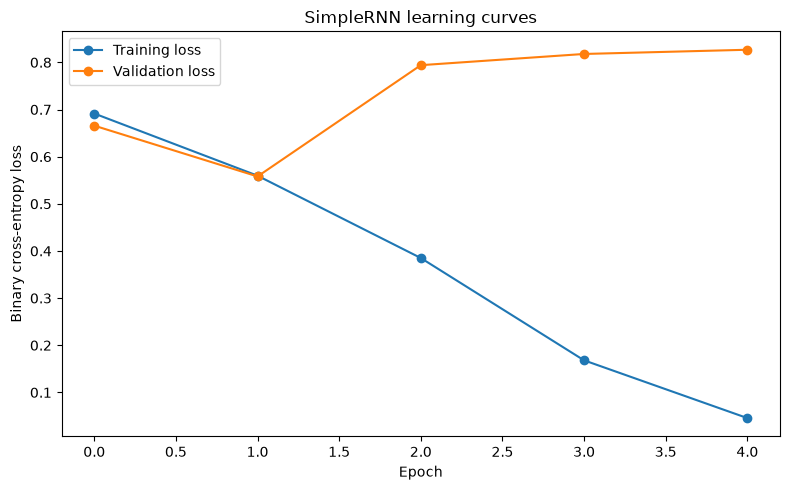

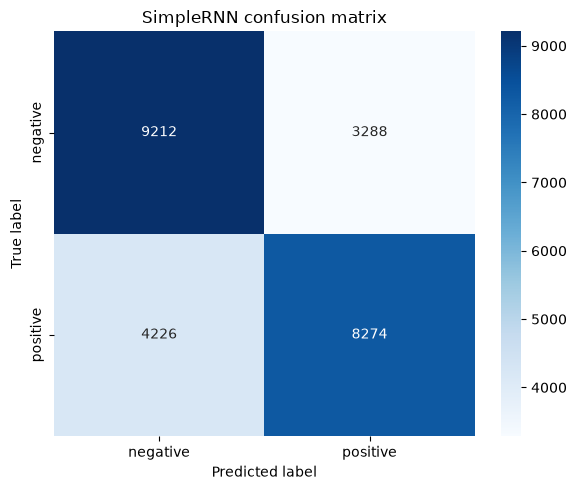

              precision    recall  f1-score   support

    negative       0.69      0.74      0.71     12500
    positive       0.72      0.66      0.69     12500

    accuracy                           0.70     25000
   macro avg       0.70      0.70      0.70     25000
weighted avg       0.70      0.70      0.70     25000



In [26]:
primary_model, primary_history, primary_pred, primary_prob, primary_row = recurrent_runs["SimpleRNN"]

plt.figure(figsize=(8, 5))
plt.plot(primary_history.history["loss"], marker="o", label="Training loss")
plt.plot(primary_history.history["val_loss"], marker="o", label="Validation loss")
plt.title("SimpleRNN learning curves")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=160)
plt.show()

cm = confusion_matrix(y_test_arr, primary_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.title("SimpleRNN confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=160)
plt.show()

print(classification_report(y_test_arr, primary_pred,
                            target_names=["negative", "positive"], zero_division=0))

**Model có dấu hiệu overfitting không?**
> Có. Mô hình SimpleRNN có dấu hiệu overfitting rõ rệt. Từ epoch 1 trở đi, training loss tiếp tục giảm, từ khoảng 0,56 xuống 0,05, trong khi validation loss tăng từ khoảng 0,56 lên 0,82. Điều này cho thấy mô hình ngày càng học tốt trên tập huấn luyện nhưng khả năng tổng quát hóa trên dữ liệu chưa thấy lại kém đi.

## 10. Error analysis data export

Export at least 3 correct and 3 incorrect SimpleRNN predictions.

In [27]:
error_df = pd.DataFrame({
    "text": test_texts,
    "true_label": np.where(y_test_arr == 1, "positive", "negative"),
    "predicted_label": np.where(primary_pred == 1, "positive", "negative"),
    "positive_probability": primary_prob,
    "correct": primary_pred == y_test_arr
})
error_df["prediction_confidence"] = np.where(
    primary_pred == 1, primary_prob, 1 - primary_prob
)

correct_examples = error_df[error_df["correct"]].head(3)
incorrect_examples = error_df[~error_df["correct"]].head(3)
display(correct_examples)
display(incorrect_examples)

error_export = pd.concat([correct_examples, incorrect_examples], ignore_index=True)
error_export.to_csv("error_analysis_examples.csv", index=False)
print("Saved error_analysis_examples.csv. Use it to select/analyze >=3 correct and >=3 incorrect cases.")

,text,true_label,predicted_label,positive_probability,correct,prediction_confidence
0,please give this one a miss br br kristy swans...,negative,negative,0.008869,True,0.991131
1,this film requires a lot of patience because i...,positive,positive,0.998241,True,0.998241
2,many animation buffs consider the great forgot...,positive,positive,0.786935,True,0.786935


,text,true_label,predicted_label,positive_probability,correct,prediction_confidence
6,originally supposed to be just a part of a hug...,positive,negative,0.098054,False,0.901946
13,i started watching this because i thought it w...,negative,positive,0.545698,False,0.545698
29,the back of the dvd for this movie raves is th...,negative,positive,0.584489,False,0.584489


Saved error_analysis_examples.csv. Use it to select/analyze >=3 correct and >=3 incorrect cases.


## 11. Compare with average Word2Vec + Logistic Regression

This is an optional lightweight approximation of the LAB04 Average Word2Vec baseline. It trains Word2Vec embeddings on the training reviews and averages word vectors per review.

In [28]:
try:
    from gensim.models import Word2Vec

    tokenized_train = [text.split() for text in X_train_text]
    tokenized_test = [text.split() for text in test_texts]

    w2v = Word2Vec(
        sentences=tokenized_train, vector_size=100, window=5,
        min_count=2, workers=1, seed=SEED, epochs=10
    )

    def average_vector(tokens, model, vector_size=100):
        vectors = [model.wv[t] for t in tokens if t in model.wv]
        if not vectors:
            return np.zeros(vector_size, dtype=np.float32)
        return np.mean(vectors, axis=0)

    X_train_avg = np.vstack([average_vector(t, w2v) for t in tokenized_train])
    X_test_avg = np.vstack([average_vector(t, w2v) for t in tokenized_test])
    avg_lr = LogisticRegression(max_iter=1000, random_state=SEED)
    avg_start = time.perf_counter()
    avg_lr.fit(X_train_avg, y_train_arr)
    avg_seconds = time.perf_counter() - avg_start
    avg_pred = avg_lr.predict(X_test_avg)
    avg_row = metric_row("Average Word2Vec + Logistic Regression", y_test_arr,
                         avg_pred, avg_seconds, params=100, vocab_size=len(w2v.wv))
    results_rows.append(avg_row)
    print(pd.DataFrame([avg_row]).to_string(index=False))
except ImportError:
    print("gensim not installed; skip this optional comparison or install with: pip install gensim")

      experiment                                  model max_length  vocab_size  parameters epochs  training_time_seconds tokens_retained_pct validation_loss  accuracy  precision  recall       f1
model_comparison Average Word2Vec + Logistic Regression       None       19991         100   None               0.065304                None            None   0.84332   0.846452  0.8388 0.842609


**RNN/LSTM/GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?**
> RNN/LSTM/GRU xử lý từ theo thứ tự xuất hiện và có khả năng học ngữ cảnh giữa các từ. Trong khi đó, Average Word2Vec lấy trung bình vector của các từ nên làm mất thông tin về thứ tự từ và khó nắm bắt các câu phủ định hoặc sự thay đổi ý nghĩa theo ngữ cảnh.

**RNN/LSTM/GRU vẫn còn vấn đề gì?**
> Các mô hình này vẫn có thể gặp hiện tượng overfitting, tốn thời gian huấn luyện và khó học các phụ thuộc dài hạn, đặc biệt với RNN đơn giản. Kết quả thực nghiệm cũng cho thấy mô hình phức tạp hơn không đảm bảo hiệu suất cao hơn: Average Word2Vec + Logistic Regression đạt F1-score khoảng 0,8426, cao hơn SimpleRNN và LSTM trong kết quả trước đó.

## 12. Try the trained model on custom reviews

Test at least one short review, one long review, a negation, and a contrast example. Replace/add examples as needed.

In [29]:
custom_reviews = [
    "Great acting and a wonderful story.",
    "This movie is not good.",
    "The film starts slowly, but the ending is excellent.",
    ("The movie has a long setup, many side characters, several scenes that do not move the plot, "
     "and a complicated middle section, but the final act is moving and the performances are excellent.")
]

def encode_custom_review(text):
    ids = [1]
    for word in text.lower().split():
        word = "".join(ch for ch in word if ch.isalnum() or ch == "'")
        if not word:
            continue
        raw_idx = word_index.get(word)
        token_id = raw_idx + 3 if raw_idx is not None and raw_idx + 3 < VOCAB_SIZE else 2
        ids.append(token_id)
    return ids

custom_ids = [encode_custom_review(t) for t in custom_reviews]
custom_pad = pad_data(custom_ids, MAX_LENGTH)
custom_probs = recurrent_runs["SimpleRNN"][0].predict(custom_pad, verbose=0).ravel()
custom_results = pd.DataFrame({
    "review": custom_reviews,
    "positive_probability": custom_probs,
    "prediction": np.where(custom_probs >= 0.5, "positive", "negative")
})
display(custom_results)

,review,positive_probability,prediction
0,Great acting and a wonderful story.,0.984191,positive
1,This movie is not good.,0.350969,negative
2,"The film starts slowly, but the ending is exce...",0.366439,negative
3,"The movie has a long setup, many side characte...",0.999404,positive


**Những từ hoặc đoạn context nào có khả năng ảnh hưởng tới prediction?**
> Những từ và ngữ cảnh có thể ảnh hưởng đến dự đoán gồm các từ mang cảm xúc như “great”, “wonderful”, “not good”, “slowly”, “excellent” và các cụm thể hiện sự tương phản như “but the ending”. Ngoài ra, mô hình có thể chú ý đến các từ như “long setup” hoặc “many side characters”, nhưng chưa chắc hiểu đúng ý nghĩa trong toàn bộ câu. Kết quả cho thấy mô hình có thể nhận diện một số từ cảm xúc, nhưng vẫn có khả năng dự đoán sai khi cần kết hợp nhiều thông tin trong ngữ cảnh.

## 13. Save results and final artifact check

In [30]:
# Include all completed experiments in the final results table.
results_df = pd.DataFrame(results_rows)
results_df.to_csv("results.csv", index=False)
display(results_df)

print("Files expected after running:")
for filename in [
    "results.csv",
    "sequence_length_histogram.png",
    "learning_curves.png",
    "confusion_matrix.png",
    "max_length_vs_f1.png",
    "max_length_vs_training_time.png",
    "error_analysis_examples.csv",
]:
    print(f"- {filename}: {'OK' if Path(filename).exists() else 'not created yet'}")

,experiment,model,max_length,vocab_size,parameters,epochs,training_time_seconds,tokens_retained_pct,validation_loss,accuracy,precision,recall,f1
0,model_comparison,TF-IDF + Logistic Regression,NaN,19179,19179,NaN,5.338891,NaN,NaN,0.88256,0.881279,0.88424,0.882757
1,model_comparison,SimpleRNN,200.0,20000,1288321,5.0,31.862174,68.235899,0.558048,0.69944,0.715620,0.66192,0.687723
2,model_comparison,LSTM,200.0,20000,1313089,5.0,70.921714,68.235899,0.396706,0.79616,0.763338,0.85848,0.808118
3,model_comparison,GRU,200.0,20000,1305025,5.0,69.914857,68.235899,0.365518,0.81744,0.821765,0.81072,0.816205
4,model_comparison,Average Word2Vec + Logistic Regression,NaN,19991,100,NaN,0.065304,NaN,NaN,0.84332,0.846452,0.83880,0.842609


Files expected after running:
- results.csv: OK
- sequence_length_histogram.png: OK
- learning_curves.png: OK
- confusion_matrix.png: OK
- max_length_vs_f1.png: OK
- max_length_vs_training_time.png: OK
- error_analysis_examples.csv: OK
